# Foundations of Generative AI (ICT4403) — Assignment 2
## Word-Level Autoregressive Shakespeare Text Generation with Simple RNN, Bidirectional RNN, LSTM and GRU

**Goal.** Train four recurrent language models under identical conditions to predict the next word of Shakespearean
text, compare them quantitatively (loss, perplexity, accuracy, training time) and qualitatively (coherence, diversity,
contextual consistency, repetition), and study how the sampling temperature changes the generated text.

*Executed on Google Colab (T4 GPU); all outputs below are from that run. Results are also saved in `results/`.*

## 1. Setup

In [2]:
import os, re, time, json, shutil
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

SEED = 42
keras.utils.set_random_seed(SEED)

CFG = dict(
    vocab_size=10_000,
    seq_len=20,
    embed_dim=128,
    hidden=256,
    dropout=0.2,
    batch_size=256,
    lr=1e-3,
    epochs=int(os.environ.get("EPOCHS", 20)),
    patience=3,
    val_frac=0.10,
)
OUT = "results"
os.makedirs(OUT, exist_ok=True)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))
CFG

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


{'vocab_size': 10000,
 'seq_len': 20,
 'embed_dim': 128,
 'hidden': 256,
 'dropout': 0.2,
 'batch_size': 256,
 'lr': 0.001,
 'epochs': 20,
 'patience': 3,
 'val_frac': 0.1}

## 2. Dataset — Tiny Shakespeare

* **Source:** Andrej Karpathy's *char-rnn* repository —
  <https://github.com/karpathy/char-rnn/tree/master/data/tinyshakespeare>
  (raw file: <https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt>).

In [3]:
path = keras.utils.get_file("tinyshakespeare.txt",
    "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt")
raw = open(path, encoding="utf-8").read()

words = re.findall(r"[A-Za-z']+", raw)
speakers = re.findall(r"^([A-Z][A-Za-z ]+):$", raw, flags=re.M)
stats = {
    "characters": len(raw),
    "lines": raw.count("\n"),
    "words": len(words),
    "unique words (case-folded)": len({w.lower() for w in words}),
    "speeches (speaker turns)": len(speakers),
    "distinct speakers": len(set(speakers)),
    "avg words per speech": round(len(words) / max(len(speakers), 1), 1),
}
display(pd.Series(stats, name="value").to_frame())
print(raw[:500])

1115394/1115394 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


,value
characters,1115394.0
lines,40000.0
words,204062.0
unique words (case-folded),12631.0
speeches (speaker turns),7805.0
distinct speakers,892.0
avg words per speech,26.1


First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


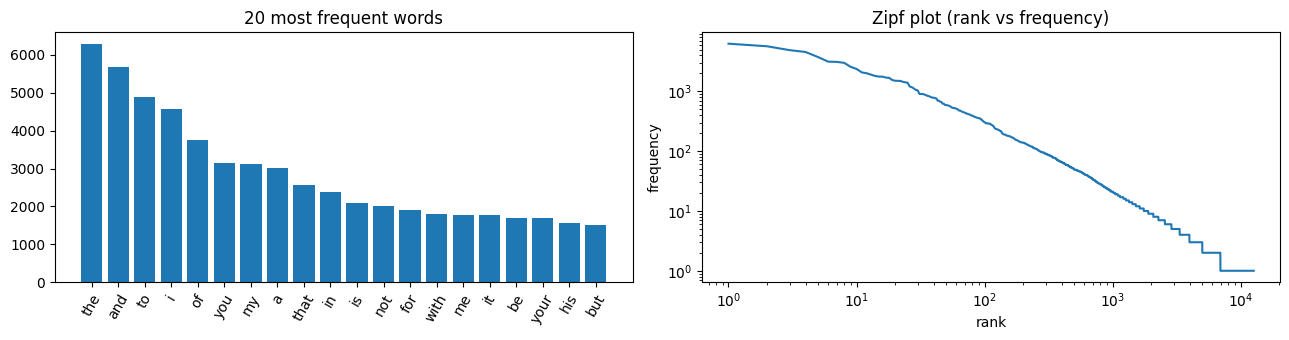

5704 words occur only once (hapax legomena)


In [4]:
freq = Counter(w.lower() for w in words)
top = pd.DataFrame(freq.most_common(20), columns=["word", "count"])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].bar(top.word, top["count"]); ax[0].set_title("20 most frequent words"); ax[0].tick_params(axis="x", rotation=60)
ranks = np.arange(1, len(freq) + 1)
ax[1].loglog(ranks, sorted(freq.values(), reverse=True)); ax[1].set_title("Zipf plot (rank vs frequency)")
ax[1].set_xlabel("rank"); ax[1].set_ylabel("frequency")
plt.tight_layout(); plt.savefig(f"{OUT}/dataset_word_freq.png", dpi=120); plt.show()
print(f"{sum(c == 1 for c in freq.values())} words occur only once (hapax legomena)")

## 3. Pre-processing

In [5]:
TOKEN_RE = re.compile(r"\n\n|\n|[a-z']+|[.,!?;:\-]")
tokenize = lambda s: TOKEN_RE.findall(re.sub(r"\n{3,}", "\n\n", s.lower()))

tokens = tokenize(raw)
counts = Counter(tokens)
itos = ["<pad>", "<unk>"] + [w for w, _ in counts.most_common(CFG["vocab_size"])]
stoi = {w: i for i, w in enumerate(itos)}
V = len(itos)
encode = lambda toks: np.array([stoi.get(t, 1) for t in toks], dtype=np.int32)

ids = encode(tokens)
coverage = (ids != 1).mean()
print(f"tokens: {len(tokens):,} | distinct tokens: {len(counts):,} | vocab size V = {V:,}")
print(f"vocabulary coverage: {coverage:.2%} of running tokens (rest -> <unk>)")
print(tokens[:40])

tokens: 285,045 | distinct tokens: 12,640 | vocab size V = 10,002
vocabulary coverage: 99.07% of running tokens (rest -> <unk>)
['first', 'citizen', ':', '\n', 'before', 'we', 'proceed', 'any', 'further', ',', 'hear', 'me', 'speak', '.', '\n\n', 'all', ':', '\n', 'speak', ',', 'speak', '.', '\n\n', 'first', 'citizen', ':', '\n', 'you', 'are', 'all', 'resolved', 'rather', 'to', 'die', 'than', 'to', 'famish', '?', '\n\n', 'all']


## 4. Input–target sequences for autoregressive modelling


In [6]:
def make_windows(arr, L=CFG["seq_len"]):
    w = np.lib.stride_tricks.sliding_window_view(arr, L + 1)
    return w[:, :-1].copy(), w[:, -1].copy()

split = int(len(ids) * (1 - CFG["val_frac"]))
X_tr, y_tr = make_windows(ids[:split])
X_va, y_va = make_windows(ids[split:])
print("train:", X_tr.shape, y_tr.shape, "| val:", X_va.shape, y_va.shape)

decode = lambda seq: " ".join(itos[i] for i in seq).replace("\n", "\\n")
for i in (0, 1, 2):
    print(f"[{decode(X_tr[i])}]  ->  {decode([y_tr[i]])}")

train_ds = (tf.data.Dataset.from_tensor_slices((X_tr, y_tr))
            .shuffle(len(X_tr), seed=SEED).batch(CFG["batch_size"]).prefetch(tf.data.AUTOTUNE))
val_ds = tf.data.Dataset.from_tensor_slices((X_va, y_va)).batch(CFG["batch_size"]).prefetch(tf.data.AUTOTUNE)

train: (256520, 20) (256520,) | val: (28485, 20) (28485,)
[first citizen : \n before we proceed any further , hear me speak . \n\n all : \n speak ,]  ->  speak
[citizen : \n before we proceed any further , hear me speak . \n\n all : \n speak , speak]  ->  .
[: \n before we proceed any further , hear me speak . \n\n all : \n speak , speak .]  ->  \n\n


## 5. Models

All four models share the same architecture except for the recurrent layer:

`Embedding(V, 128) → recurrent layer (256-d output) → Dropout(0.2) → Dense(V, softmax)`

| Model | Recurrent layer | Idea |
|---|---|---|
| Simple RNN | `SimpleRNN(256)` | $h_t=\tanh(W x_t + U h_{t-1} + b)$; suffers from vanishing gradients on long contexts |
| Bidirectional RNN | `Bidirectional(SimpleRNN(128))` | one RNN reads the context window left→right, another right→left; outputs concatenated (128+128=256) |
| LSTM | `LSTM(256)` | input/forget/output gates + cell state keep long-range information |
| GRU | `GRU(256)` | update/reset gates; LSTM-like memory with fewer parameters |

*Note on the BiRNN:* it reads only the 20-token **context** in both directions; the target word lies outside the window,
so there is no information leak, and generation remains strictly left-to-right (autoregressive).

In [7]:
RNN_LAYERS = {
    "SimpleRNN": lambda: keras.layers.SimpleRNN(CFG["hidden"]),
    "BiRNN":     lambda: keras.layers.Bidirectional(keras.layers.SimpleRNN(CFG["hidden"] // 2)),
    "LSTM":      lambda: keras.layers.LSTM(CFG["hidden"]),
    "GRU":       lambda: keras.layers.GRU(CFG["hidden"]),
}

def build(name):
    keras.utils.set_random_seed(SEED)  # same initialisation conditions for every model
    model = keras.Sequential([
        keras.Input(shape=(CFG["seq_len"],), dtype="int32"),
        keras.layers.Embedding(V, CFG["embed_dim"]),
        RNN_LAYERS[name](),
        keras.layers.Dropout(CFG["dropout"]),
        keras.layers.Dense(V, activation="softmax"),
    ], name=name)
    model.compile(optimizer=keras.optimizers.Adam(CFG["lr"]),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(5, name="top5")])
    return model

for n in RNN_LAYERS:
    build(n).summary()

Model: "SimpleRNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 20, 128)        │     1,280,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 256)            │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10002)          │     2,570,514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,949,330 (15.07 MB)

 Trainable params: 3,949,330 (15.07 MB)

 Non-trainable params: 0 (0.00 B)

...

Model: "GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 20, 128)        │     1,280,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 256)            │       296,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10002)          │     2,570,514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,147,218 (15.82 MB)

 Trainable params: 4,147,218 (15.82 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Training under comparable conditions

Same data, batch size (256), optimiser (Adam, lr = 1e-3), loss (sparse categorical cross-entropy), maximum epochs (20),
and early stopping on validation loss (patience 3, best weights restored) for every model. Wall-clock time is measured
around `fit`.

In [8]:
models, histories, train_time = {}, {}, {}
for name in RNN_LAYERS:
    print(f"\n===== {name} =====")
    model = build(name)
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=CFG["patience"], restore_best_weights=True)
    t0 = time.perf_counter()
    h = model.fit(train_ds, validation_data=val_ds, epochs=CFG["epochs"], callbacks=[es], verbose=2)
    train_time[name] = time.perf_counter() - t0
    models[name], histories[name] = model, h.history
    print(f"{name}: {train_time[name]:.1f}s, {len(h.history['loss'])} epochs")

json.dump({n: {k: [float(v) for v in vs] for k, vs in h.items()} for n, h in histories.items()},
          open(f"{OUT}/histories.json", "w"), indent=1)


===== SimpleRNN =====
Epoch 1/20
1003/1003 - 17s - 17ms/step - accuracy: 0.1409 - loss: 5.8788 - top5: 0.2825 - val_accuracy: 0.2164 - val_loss: 5.1554 - val_top5: 0.3641
Epoch 2/20
1003/1003 - 7s - 7ms/step - accuracy: 0.2113 - loss: 4.9148 - top5: 0.3791 - val_accuracy: 0.2261 - val_loss: 4.8926 - val_top5: 0.4094
Epoch 3/20
1003/1003 - 7s - 7ms/step - accuracy: 0.2276 - loss: 4.6191 - top5: 0.4080 - val_accuracy: 0.2412 - val_loss: 4.8121 - val_top5: 0.4163
Epoch 4/20
1003/1003 - 7s - 7ms/step - accuracy: 0.2383 - loss: 4.4086 - top5: 0.4245 - val_accuracy: 0.2463 - val_loss: 4.8096 - val_top5: 0.4246
Epoch 5/20
1003/1003 - 7s - 7ms/step - accuracy: 0.2478 - loss: 4.2266 - top5: 0.4372 - val_accuracy: 0.2476 - val_loss: 4.8209 - val_top5: 0.4284
Epoch 6/20
1003/1003 - 7s - 7ms/step - accuracy: 0.2577 - loss: 4.0633 - top5: 0.4505 - val_accuracy: 0.2468 - val_loss: 4.8576 - val_top5: 0.4213
Epoch 7/20
1003/1003 - 7s - 7ms/step - accuracy: 0.2671 - loss: 3.9151 - top5: 0.4654 - val_a

## 7. Quantitative evaluation

In [9]:
rows = []
for name, model in models.items():
    loss, acc, top5 = model.evaluate(val_ds, verbose=0)
    ep = len(histories[name]["loss"])
    rows.append({
        "model": name, "params": model.count_params(),
        "epochs_run": ep, "best_epoch": int(np.argmin(histories[name]["val_loss"])) + 1,
        "train_loss": histories[name]["loss"][int(np.argmin(histories[name]["val_loss"]))],
        "val_loss": loss, "val_perplexity": float(np.exp(loss)),
        "val_top1_acc": acc, "val_top5_acc": top5,
        "train_time_s": train_time[name], "sec_per_epoch": train_time[name] / ep,
    })
metrics = pd.DataFrame(rows).set_index("model")
metrics.to_csv(f"{OUT}/metrics.csv")
metrics.round(4)

,params,epochs_run,best_epoch,train_loss,val_loss,val_perplexity,val_top1_acc,val_top5_acc,train_time_s,sec_per_epoch
model,,,,,,,,,,
SimpleRNN,3949330,7,4,4.4086,4.8096,122.6851,0.2463,0.4246,62.0180,8.8597
BiRNN,3916562,6,3,4.4826,4.8136,123.1794,0.2385,0.4158,60.2164,10.0361
LSTM,4245010,8,5,4.3656,4.8304,125.2633,0.2496,0.4305,131.2241,16.4030
GRU,4147218,7,4,4.2515,4.6804,107.8088,0.2539,0.4433,105.9547,15.1364


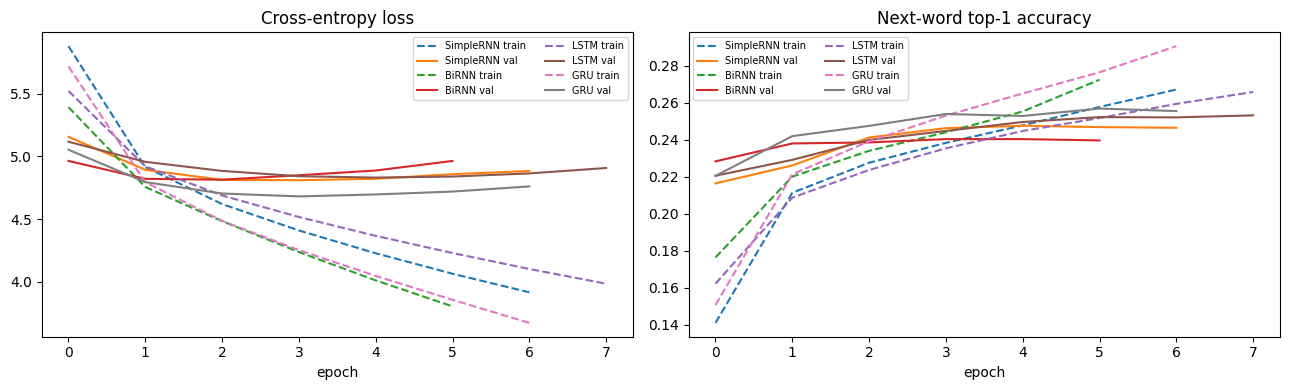

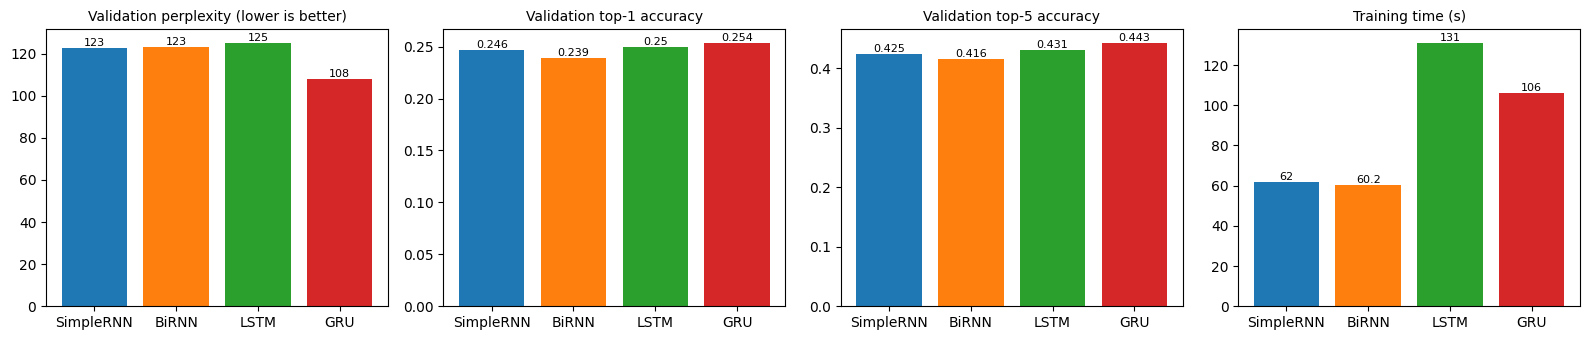

In [10]:
names = list(models)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for n in names:
    ax[0].plot(histories[n]["loss"], "--", label=f"{n} train")
    ax[0].plot(histories[n]["val_loss"], label=f"{n} val")
    ax[1].plot(histories[n]["accuracy"], "--", label=f"{n} train")
    ax[1].plot(histories[n]["val_accuracy"], label=f"{n} val")
ax[0].set_title("Cross-entropy loss"); ax[1].set_title("Next-word top-1 accuracy")
for a in ax: a.set_xlabel("epoch"); a.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(f"{OUT}/loss_accuracy_curves.png", dpi=120); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, col, title in zip(ax, ["val_perplexity", "val_top1_acc", "val_top5_acc", "train_time_s"],
                         ["Validation perplexity (lower is better)", "Validation top-1 accuracy",
                          "Validation top-5 accuracy", "Training time (s)"]):
    a.bar(names, metrics[col], color=["tab:blue", "tab:orange", "tab:green", "tab:red"])
    a.set_title(title, fontsize=10)
    for i, v in enumerate(metrics[col]): a.text(i, v, f"{v:.3g}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/model_comparison.png", dpi=120); plt.show()

## 8. Autoregressive text generation with temperature sampling

At each step the last 20 tokens are fed to the model, the predicted distribution $p$ is re-scaled with temperature $T$,
$p_i^{(T)} \propto \exp(\log p_i / T)$, one token is sampled and appended, and the process repeats for 60 tokens.
`<unk>`/`<pad>` are never sampled. Every (model, seed, T) combination uses the same random-number seed, so differences
come from the models and the temperature only.

* $T<1$ sharpens the distribution (safer, more repetitive); $T=1$ samples the model's own distribution;
  $T>1$ flattens it (more diverse, less coherent).

In [11]:
SEEDS = [
    "first citizen :\nbefore we proceed any further , hear me speak .",
    "king richard :\nmy lord , what news",
    "romeo :\no , she doth teach the torches to burn bright",
]
TEMPS = [0.5, 1.0, 1.5]
GEN_LEN = 60

def detok(toks):
    s = " ".join(toks)
    s = re.sub(r" ?(\n\n?) ?", r"\1", s)
    return re.sub(r" ([.,!?;:])", r"\1", s)

def generate(model, seed_text, n=GEN_LEN, temperature=1.0, rng_seed=SEED):
    rng = np.random.default_rng(rng_seed)
    ctx = list(encode(tokenize(seed_text)))
    out = []
    for _ in range(n):
        x = np.array([([0] * CFG["seq_len"] + ctx)[-CFG["seq_len"]:]], dtype=np.int32)
        p = model(x, training=False).numpy()[0].astype("float64")
        logp = np.log(p + 1e-12) / temperature
        logp[:2] = -np.inf
        p = np.exp(logp - logp.max()); p /= p.sum()
        nxt = int(rng.choice(V, p=p))
        ctx.append(nxt); out.append(itos[nxt])
    return out

samples = []
for name, model in models.items():
    for si, seed in enumerate(SEEDS):
        for T in TEMPS:
            samples.append({"model": name, "seed_id": si, "temperature": T, "seed": seed,
                            "tokens": generate(model, seed, temperature=T)})

with open(f"{OUT}/generated_samples.txt", "w") as f:
    for s in samples:
        f.write(f"===== {s['model']} | seed {s['seed_id']} | T={s['temperature']} =====\n")
        f.write(f"[SEED] {s['seed']}\n[GENERATED] {detok(s['tokens'])}\n\n")
print(open(f"{OUT}/generated_samples.txt").read()[:3000])

===== SimpleRNN | seed 0 | T=0.5 =====
[SEED] first citizen :
before we proceed any further , hear me speak .
[GENERATED] 

duke vincentio:
gentle lords,
that i may have an been a tongue
with this wife, i'll leave thy life.
to do not alone, i will not be a man.

friar laurence:
o, i do the king, that i would do you
the king

===== SimpleRNN | seed 0 | T=1.0 =====
[SEED] first citizen :
before we proceed any further , hear me speak .
[GENERATED] 

juliet:
i spy where where i was but amazed for words.

angelo:
'tis cry a complainings there did me be:
their boots going to his youth,
so which we say them well. if they do it not
my all slow than father's paper.

duke of

===== SimpleRNN | seed 0 | T=1.5 =====
[SEED] first citizen :
before we proceed any further , hear me speak .
[GENERATED] and many impatience will
haunted deserved sport. come for o'erpast such beauty's pride,
and consume ere folly for lots incur respected and business
in circumstance crack'd fines; whose oak and king!
ratc

In [12]:
for si, seed in enumerate(SEEDS):
    print("#" * 100, f"\nSEED {si}: {seed!r}\n")
    for s in samples:
        if s["seed_id"] == si:
            print(f"--- {s['model']:9s} T={s['temperature']} ---\n{detok(s['tokens'])}\n")

#################################################################################################### 
SEED 0: 'first citizen :\nbefore we proceed any further , hear me speak .'

--- SimpleRNN T=0.5 ---


duke vincentio:
gentle lords,
that i may have an been a tongue
with this wife, i'll leave thy life.
to do not alone, i will not be a man.

friar laurence:
o, i do the king, that i would do you
the king

--- SimpleRNN T=1.0 ---


juliet:
i spy where where i was but amazed for words.

angelo:
'tis cry a complainings there did me be:
their boots going to his youth,
so which we say them well. if they do it not
my all slow than father's paper.

duke of

--- SimpleRNN T=1.5 ---
and many impatience will
haunted deserved sport. come for o'erpast such beauty's pride,
and consume ere folly for lots incur respected and business
in circumstance crack'd fines; whose oak and king!
ratcliff in growth burns for hereditary corpse; my perpetual,
the feverous brains free compassion us pluck,


--- BiRNN 

## 9. Diversity, repetition and consistency metrics of the generated text


In [13]:
def distinct(toks, n):
    grams = list(zip(*[toks[i:] for i in range(n)]))
    return len(set(grams)) / max(len(grams), 1)

def repetition(toks, n=3):
    return 1 - distinct(toks, n)

judge_name = metrics["val_perplexity"].idxmin()
judge = models[judge_name]

def judged_ppl(seed, toks):
    seq = list(encode(tokenize(seed))) + [stoi[t] for t in toks]
    k = len(seq) - len(toks)
    X = np.array([([0] * CFG["seq_len"] + seq[:i])[-CFG["seq_len"]:] for i in range(k, len(seq))], dtype=np.int32)
    p = judge.predict(X, verbose=0)[np.arange(len(toks)), seq[k:]]
    return float(np.exp(-np.mean(np.log(p + 1e-12))))

for s in samples:
    words_only = [t for t in s["tokens"] if t not in ("\n", "\n\n")]
    s.update(distinct_1=distinct(words_only, 1), distinct_2=distinct(words_only, 2),
             repetition_3gram=repetition(words_only), judged_perplexity=judged_ppl(s["seed"], s["tokens"]))

tm = (pd.DataFrame(samples)
      .groupby(["model", "temperature"])[["distinct_1", "distinct_2", "repetition_3gram", "judged_perplexity"]]
      .mean())
tm.to_csv(f"{OUT}/temperature_metrics.csv")
print(f"coherence judge = {judge_name}")
tm.round(3)

coherence judge = GRU


distinct_1  distinct_2  repetition_3gram  \
model     temperature                                             
BiRNN     0.5               0.654       0.921             0.027   
          1.0               0.799       1.000             0.000   
          1.5               0.939       1.000             0.000   
GRU       0.5               0.676       0.947             0.007   
          1.0               0.748       0.987             0.000   
          1.5               0.920       1.000             0.000   
LSTM      0.5               0.679       0.948             0.013   
          1.0               0.794       0.993             0.000   
          1.5               0.879       1.000             0.000   
SimpleRNN 0.5               0.647       0.908             0.047   
          1.0               0.814       0.994             0.000   
          1.5               0.866       1.000             0.000   

                       judged_perplexity  
model     temperature                     
BiRNN     0.5                     20.703  
          1.0                    148.886  
          1.5                   4521.594  
GRU       0.5                     10.591  
          1.0                     79.144  
          1.5                   1607.116  
LSTM      0.5                     16.199  
          1.0                     84.977  
          1.5                    883.277  
SimpleRNN 0.5                     17.608  
          1.0                    105.990  
          1.5                   1615.604

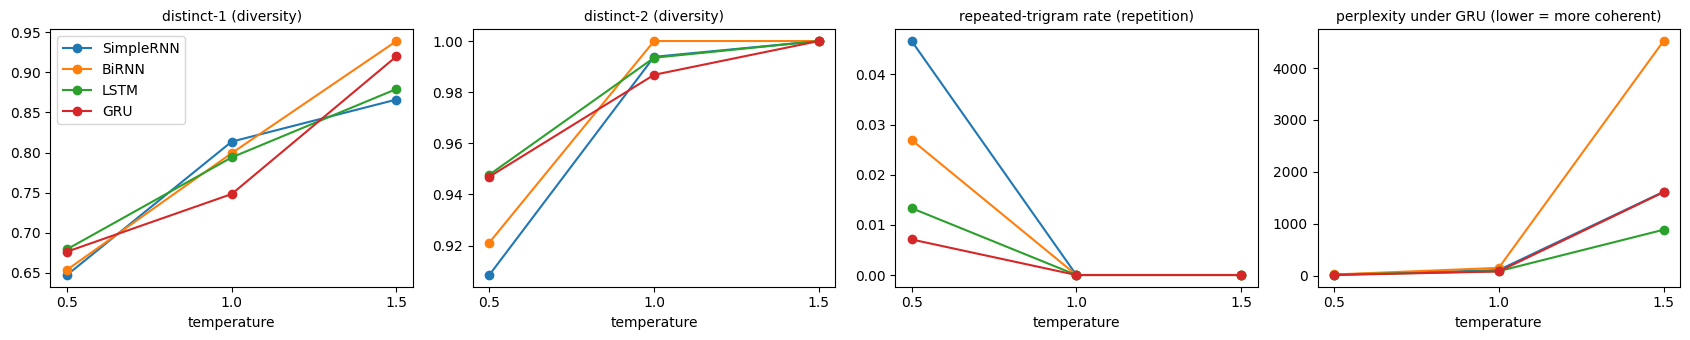

In [14]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.5))
for a, col, title in zip(ax, tm.columns, ["distinct-1 (diversity)", "distinct-2 (diversity)",
                                          "repeated-trigram rate (repetition)",
                                          f"perplexity under {judge_name} (lower = more coherent)"]):
    for n in names:
        a.plot(TEMPS, tm.loc[n, col], marker="o", label=n)
    a.set_title(title, fontsize=10); a.set_xlabel("temperature"); a.set_xticks(TEMPS)
ax[0].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/temperature_effect.png", dpi=120); plt.show()

## 10. Analysis

### 10.1 Quantitative comparison (validation set, best-epoch weights)

| Model | Params | Epochs run (best) | Val loss | **Perplexity** | Top-1 acc | Top-5 acc | Train time | s/epoch |
|---|---|---|---|---|---|---|---|---|
| Simple RNN | 3.95 M | 7 (4) | 4.810 | 122.7 | 24.6 % | 42.5 % | 62 s | 8.9 |
| Bidirectional RNN | 3.92 M | 6 (3) | 4.814 | 123.2 | 23.9 % | 41.6 % | 60 s | 10.0 |
| LSTM | 4.25 M | 8 (5) | 4.830 | 125.3 | 25.0 % | 43.1 % | 131 s | 16.4 |
| **GRU** | 4.15 M | 7 (4) | **4.680** | **107.8** | **25.4 %** | **44.3 %** | 106 s | 15.1 |

* **GRU is clearly best on every predictive metric**: its perplexity is ~12 % lower than the other three models, which are
  within 2 % of each other. It also has the highest top-1 and top-5 accuracy.
* **All models overfit quickly.** Training loss keeps falling, but validation loss reaches its minimum at epoch 3–5 and then rises.
  This is expected for ~260 k training windows against a 10 k-word softmax. Early stopping restored the best weights, so the comparison is fair.
* **Training time:** Simple/Bi-RNN are the cheapest (~60 s). The gated models cost ~1.5–2× more per epoch. GRU (3 gates' worth of
  weights vs LSTM's 4) is faster than LSTM and converged in fewer epochs.
* **Simple RNN vs LSTM on perplexity:** with a short 20-token window the vanishing-gradient problem is mild, so the Simple RNN's
  next-word perplexity is competitive. Its weakness shows in *generation* (below), where context has to be carried across many steps.
* **Bidirectional RNN gives no gain.** The target word lies *after* the window, so the backward pass adds little information
  beyond the forward pass, and each direction has only 128 units. It is also not a natural generator: it must re-read the whole window at every step.

### 10.2 Qualitative comparison of generated text (see `results/generated_samples.txt`)

| | Coherence | Diversity | Contextual consistency | Repetition |
|---|---|---|---|---|
| Simple RNN | Locally grammatical fragments only | Medium | **Poor**: for seeds 1 and 2 at T=0.5 it produces the *same* continuation ("…, sir, you have done, sir, / i have no more than the boar - day, …"), so the seed is forgotten within ~2 tokens | Highest (4.7 % repeated trigrams at T=0.5) |
| Bidirectional RNN | Fair; frequent ungrammatical clauses | Medium | Weak; drifts away from the seed | Loops on phrases ("the world, to thee the work of the world") |
| LSTM | Good speaker/line structure | High | Fair | Occasional degenerate runs ("to - - - - -") |
| **GRU** | **Best**: e.g. *"king richard: my lord, what news is a traitor. welcome, come, i will not do your grace"*, *"what! you have no need to be a king, that is a sin of all the noble"* | High | **Best**; keeps the seed's register (king/lord/grace) | **Lowest** (0.7 % at T=0.5) |

All four models learned the play-script format (speaker name → `:` → line breaks → blank line between speeches).
Within a speech, though, sentences are only locally coherent. That is typical of a word-level RNN trained on ~200 k words.

### 10.3 Influence of sampling temperature

Mean over the 3 seeds (`results/temperature_metrics.csv`, `results/temperature_effect.png`):

| T | distinct-1 (range over models) | distinct-2 | repeated-trigram rate | perplexity under GRU judge |
|---|---|---|---|---|
| 0.5 | 0.65 – 0.68 | 0.91 – 0.95 | 0.7 % – 4.7 % | 11 – 21 |
| 1.0 | 0.75 – 0.81 | 0.99 – 1.00 | 0 % | 79 – 149 |
| 1.5 | 0.87 – 0.94 | 1.00 | 0 % | 883 – 4522 |

* **T = 0.5 (sharpened):** the most coherent and grammatical text, with real speaker names and common phrases.
  It also has the lowest diversity, and it is the only setting with noticeable repetition (stock phrases "my lord", "i will not", loops).
* **T = 1.0 (model distribution):** a good balance. Vocabulary becomes much richer and repetition disappears. Speaker
  structure is kept, but grammar degrades ("i aim no knee, as a surfeit young fortune").
* **T = 1.5 (flattened):** maximal diversity but incoherent word salad. Rare words are sampled constantly, the
  script format breaks down and speaker names are invented ("duke of throne breast real friends:"). The judge perplexity explodes by 10–50×.
* So temperature trades **coherence ↔ diversity** monotonically, and repetition is a problem only at low T. A temperature of
  about **0.5–1.0** gives the best Shakespeare-like output for these models.

*Caveat:* the coherence judge is the GRU itself, which favours its own samples somewhat. The LSTM samples, however, also score well
(16 / 85 / 883), and the ranking agrees with manual reading.

### 10.4 Conclusion: best model

**The GRU provides the most effective autoregressive generation for Tiny Shakespeare.** It has the lowest validation
perplexity (107.8 vs ≥ 122.7), the highest top-1/top-5 accuracy (25.4 % / 44.3 %), the most coherent and least repetitive samples,
and the best adherence to the seed context. It is also cheaper to train than the LSTM. The LSTM is a close second in sample quality
but slower. The Simple RNN is fast but forgets its context. The Bidirectional RNN brings no benefit for next-word prediction.

In [15]:
shutil.make_archive("results", "zip", OUT)   # download results.zip from the Colab/Kaggle file browser
sorted(os.listdir(OUT))

['dataset_word_freq.png',
 'generated_samples.txt',
 'histories.json',
 'loss_accuracy_curves.png',
 'metrics.csv',
 'model_comparison.png',
 'temperature_effect.png',
 'temperature_metrics.csv']